# DE Design Checks: Seasonal/Circadian Blocker and Seasonal-Only Runs (Recalled Genera)

Two modifications to the dysbiosis DESeq2 in `transcriptomic_impact_of_dysbiosis_recalled_genera.ipynb` (`~timepoint + High_rare_genera`, rare genera < 10% prevalence, dysbiotic if > 1% of reads are rare genera):

1. **Seasonal vs circadian blocker.** `~timepoint + High_rare_genera + Seasonal_or_circadian` is **not full rank**: every circadian timepoint (`c1_*`, `c2_*`) is circadian and every seasonal one (`t*`) is seasonal, so the blocker is the sum of the circadian timepoint columns. The timepoint terms already remove any seasonal/circadian difference. The check below shows this. The closest design that can be fitted is `~Seasonal_or_circadian + High_rare_genera`, with the blocker replacing timepoint. That design only controls for the experiment, not for time within it.
2. **Seasonal samples only**, `~timepoint + High_rare_genera`, with rare genera at < 10% (dysbiotic > 1%) and < 20% (dysbiotic > 1.827%, the cutoff that gave 45 dysbiotic samples across all samples in `de_sensitivity_rare_genera_20_percent.ipynb`). The abundance cutoffs are unchanged, so only the sample set differs.

3. **Stricter cutoffs:** for rare genera at < 10% and < 20% prevalence, the abundance cutoff is raised so that only the top ~20 samples are dysbiotic (`target_n_strict`), with the original design on all samples.
4. **Luke's dysbiosis calls** (`lic_16S_gen_dysbiosis.csv`, dysbiotic if non-core genera make up ≥ 10% of reads), with the original design `~timepoint + High_rare_genera`, on all samples and on seasonal samples only. Transcriptomes without a call are counted as Low.

Gene filters (> 2000 total reads, > 1 read in more than 21 samples) are re-applied to each sample set. Timepoints are strings, so they enter the design as a categorical factor; the design-matrix check below confirms it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

In [2]:
###Define Thresholds
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
target_n_strict = 20  # dysbiotic samples for the stricter-cutoff runs
rare_cutoffs = {
    "rare < 10%": {"prevalence": 0.1, "abundance": 1.0},
    "rare < 20%": {"prevalence": 0.2, "abundance": 1.827},
}

In [3]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


## Rare genera abundance per sample (< 10% and < 20% prevalence)

In [4]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome,
    values="Abundance",
    index="Sample",
    columns="Genus",
    aggfunc="sum",
    fill_value=0,
)
genus_abundance_matrix = (
    genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100
)
seasonal_samples = plant_microbiome.loc[
    plant_microbiome["seascirc"] == "seasonal", "Sample"
].unique()
seasonal_prevalence = (genus_abundance_matrix.loc[seasonal_samples] > 0).mean()

for name, cutoff in rare_cutoffs.items():
    rare_genera = seasonal_prevalence.index[seasonal_prevalence < cutoff["prevalence"]]
    abund = trimmed_metadata["sampID"].map(genus_abundance_matrix[rare_genera].sum(axis=1))
    trimmed_metadata[f"Rare abundance ({name})"] = abund.fillna(0.0)
    trimmed_metadata[f"High ({name})"] = np.where(
        abund.fillna(0.0) > cutoff["abundance"], "High", "Low"
    )
    print(f"{name}: {len(rare_genera)} rare genera, > {cutoff['abundance']}% abundance")

luke_calls = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_dysbiosis.csv",
    index_col="sampleID",
)["Dysbiosis.Status"]
trimmed_metadata["High (Luke calls)"] = np.where(
    trimmed_metadata["sampID"].map(luke_calls) == "Dysbiotic", "High", "Low"
)
print(f"Luke calls: {(trimmed_metadata['High (Luke calls)'] == 'High').sum()} High, "
      f"{trimmed_metadata['sampID'].map(luke_calls).isna().sum()} transcriptomes without a call")

trimmed_metadata["Seasonal_or_circadian"] = np.where(
    trimmed_metadata["Experiment Type"] == "Long Term", "Seasonal", "Circadian"
)
display(
    pd.crosstab(
        [trimmed_metadata["Seasonal_or_circadian"]],
        [trimmed_metadata["High (rare < 10%)"], trimmed_metadata["High (rare < 20%)"]],
        margins=True,
    )
)
pd.crosstab(
    trimmed_metadata["Seasonal_or_circadian"], trimmed_metadata["High (Luke calls)"], margins=True
)

rare < 10%: 160 rare genera, > 1.0% abundance
rare < 20%: 180 rare genera, > 1.827% abundance
Luke calls: 126 High, 2 transcriptomes without a call


High (rare < 10%)     High      Low       All
High (rare < 20%)     High Low High  Low     
Seasonal_or_circadian                        
Circadian               10   3    2  188  203
Seasonal                28  15    5  175  223
All                     38  18    7  363  426

High (Luke calls),High,Low,All
Seasonal_or_circadian,,,
Circadian,30,173,203
Seasonal,96,127,223
All,126,300,426


## Stricter cutoffs: top ~20 samples dysbiotic

In [5]:
strict_cutoffs = {}
for name in rare_cutoffs:
    sorted_abund = (
        trimmed_metadata[f"Rare abundance ({name})"].sort_values(ascending=False).to_numpy()
    )
    # Halfway between the target-th and next-highest abundance
    strict_cutoffs[name] = round(
        (sorted_abund[target_n_strict - 1] + sorted_abund[target_n_strict]) / 2, 3
    )
    trimmed_metadata[f"High ({name}, top {target_n_strict})"] = np.where(
        trimmed_metadata[f"Rare abundance ({name})"] > strict_cutoffs[name], "High", "Low"
    )
    n_high = (trimmed_metadata[f"High ({name}, top {target_n_strict})"] == "High").sum()
    print(f"{name}: cutoff {strict_cutoffs[name]}% -> {n_high} dysbiotic")

strict_columns = [f"High ({name}, top {target_n_strict})" for name in rare_cutoffs]
display(pd.crosstab(trimmed_metadata[strict_columns[0]], trimmed_metadata[strict_columns[1]], margins=True))
pd.crosstab(
    trimmed_metadata["Seasonal_or_circadian"],
    [trimmed_metadata[column] for column in strict_columns],
)

rare < 10%: cutoff 1.719% -> 20 dysbiotic
rare < 20%: cutoff 2.655% -> 20 dysbiotic


"High (rare < 20%, top 20)",High,Low,All
"High (rare < 10%, top 20)",,,
High,15,5,20
Low,5,401,406
All,20,406,426


High (rare < 10%, top 20) High      Low     
High (rare < 20%, top 20) High Low High  Low
Seasonal_or_circadian                       
Circadian                    2   3    0  198
Seasonal                    13   2    5  203

## DESeq2 helper

In [6]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=6)


def filter_genes(counts):
    counts = counts.loc[:, counts.sum() > expressed_gene_reads_threshold]
    return counts.loc[:, (counts > 1).sum() > number_of_samples_expressed_in_threshold]


def design_matrix_check(counts, metadata, design):
    """Build the DESeq2 design matrix without fitting and report its rank."""
    with contextlib.redirect_stdout(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=counts.iloc[:, :5], metadata=metadata, design=design, quiet=True
        )
    X = dds.obsm["design_matrix"]
    rank = np.linalg.matrix_rank(X.to_numpy(dtype=float))
    print(f"{design}: {X.shape[1]} columns, rank {rank} -> {'full rank' if rank == X.shape[1] else 'NOT full rank'}")
    return X


def run_deseq(sample_index, high_column, design):
    counts = filter_genes(trimmed_raw_transcriptome.loc[sample_index])
    metadata = trimmed_metadata.loc[sample_index, ["timepoint", "Seasonal_or_circadian"]].copy()
    metadata["High_rare_genera"] = trimmed_metadata.loc[sample_index, high_column]
    X = design_matrix_check(counts, metadata, design)
    dds = pydeseq2.dds.DeseqDataSet(
        counts=counts,
        metadata=metadata,
        design=design,
        refit_cooks=True,
        inference=inference,
        quiet=True,
    )
    dds.deseq2()
    stats = pydeseq2.ds.DeseqStats(
        dds, contrast=["High_rare_genera", "High", "Low"], inference=inference, quiet=True
    )
    stats.summary()
    results = stats.results_df
    significant = results.loc[results["padj"] < 0.05]
    summary = {
        "design": design,
        "samples": len(sample_index),
        "n High": int((metadata["High_rare_genera"] == "High").sum()),
        "genes tested": counts.shape[1],
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "shared with old 59 DE genes": len(set(significant.index) & old_de_genes),
        "min padj": results["padj"].min(),
    }
    return results, summary


old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

## Timepoint coding and the blocker design

Timepoints are strings, so the formula dummy-codes them (one column per timepoint after the reference). Adding the blocker adds a column without adding rank.

In [7]:
print("timepoint dtype:", trimmed_metadata["timepoint"].dtype, "| levels:", trimmed_metadata["timepoint"].nunique())
print(pd.crosstab(trimmed_metadata["timepoint"].str.startswith("c"), trimmed_metadata["Seasonal_or_circadian"]).rename_axis(index="circadian timepoint name"))

check_metadata = trimmed_metadata[["timepoint", "Seasonal_or_circadian"]].assign(
    High_rare_genera=trimmed_metadata["High (rare < 10%)"]
)
X = design_matrix_check(trimmed_raw_transcriptome, check_metadata, "~timepoint+High_rare_genera")
print("  timepoint columns:", sum(c.startswith("timepoint[T.") for c in X.columns), "e.g.", list(X.columns[1:4]))
design_matrix_check(
    trimmed_raw_transcriptome, check_metadata, "~timepoint+High_rare_genera+Seasonal_or_circadian"
);

timepoint dtype: object | levels: 54
Seasonal_or_circadian     Circadian  Seasonal
circadian timepoint name                     
False                             0       223
True                            203         0
~timepoint+High_rare_genera: 55 columns, rank 55 -> full rank
  timepoint columns: 53 e.g. ['timepoint[T.c1_t02]', 'timepoint[T.c1_t03]', 'timepoint[T.c1_t04]']
~timepoint+High_rare_genera+Seasonal_or_circadian: 56 columns, rank 55 -> NOT full rank


/Users/michael/miniconda3/envs/Luke_terrace/lib/python3.13/site-packages/pydeseq2/dds.py:308: UserWarning: The design matrix is not full rank, so the model cannot be fitted, but some operations like design-free VST remain possible. To perform differential expression analysis, please remove the design variables that are linear combinations of others.
  self._check_full_rank_design()


## Runs

In [8]:
all_samples = trimmed_metadata.index
seasonal_only = trimmed_metadata.index[trimmed_metadata["Seasonal_or_circadian"] == "Seasonal"]

runs = {
    "All samples, ~timepoint (original)": (all_samples, "High (rare < 10%)", "~timepoint+High_rare_genera"),
    "All samples, blocker instead of timepoint": (all_samples, "High (rare < 10%)", "~Seasonal_or_circadian+High_rare_genera"),
    "Seasonal only, rare < 10%": (seasonal_only, "High (rare < 10%)", "~timepoint+High_rare_genera"),
    "Seasonal only, rare < 20%": (seasonal_only, "High (rare < 20%)", "~timepoint+High_rare_genera"),
    "All samples, rare < 10%, top 20": (all_samples, "High (rare < 10%, top 20)", "~timepoint+High_rare_genera"),
    "All samples, rare < 20%, top 20": (all_samples, "High (rare < 20%, top 20)", "~timepoint+High_rare_genera"),
    "All samples, Luke calls": (all_samples, "High (Luke calls)", "~timepoint+High_rare_genera"),
    "Seasonal only, Luke calls": (seasonal_only, "High (Luke calls)", "~timepoint+High_rare_genera"),
}

run_results = {}
run_summaries = []
for run_name, (sample_index, high_column, design) in runs.items():
    print(f"\n=== {run_name} ===")
    with contextlib.redirect_stdout(io.StringIO()):
        results, summary = run_deseq(sample_index, high_column, design)
    run_results[run_name] = results
    run_summaries.append({"run": run_name, **summary})
    print({k: v for k, v in summary.items() if k != "design"})

run_summary_df = pd.DataFrame(run_summaries).set_index("run")
run_summary_df


=== All samples, ~timepoint (original) ===


{'samples': 426, 'n High': 56, 'genes tested': 18032, 'significant (padj < 0.05)': 0, 'up': 0, 'down': 0, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.33317067030067005)}

=== All samples, blocker instead of timepoint ===


{'samples': 426, 'n High': 56, 'genes tested': 18032, 'significant (padj < 0.05)': 109, 'up': 39, 'down': 70, 'shared with old 59 DE genes': 2, 'min padj': np.float64(5.098165955816447e-06)}

=== Seasonal only, rare < 10% ===


{'samples': 223, 'n High': 43, 'genes tested': 16152, 'significant (padj < 0.05)': 0, 'up': 0, 'down': 0, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.6576230648718955)}

=== Seasonal only, rare < 20% ===


{'samples': 223, 'n High': 33, 'genes tested': 16152, 'significant (padj < 0.05)': 1, 'up': 0, 'down': 1, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.03593631081685661)}

=== All samples, rare < 10%, top 20 ===


{'samples': 426, 'n High': 20, 'genes tested': 18032, 'significant (padj < 0.05)': 0, 'up': 0, 'down': 0, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.6248607450296138)}

=== All samples, rare < 20%, top 20 ===


{'samples': 426, 'n High': 20, 'genes tested': 18032, 'significant (padj < 0.05)': 2, 'up': 0, 'down': 2, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.02891248845870609)}

=== All samples, Luke calls ===


{'samples': 426, 'n High': 126, 'genes tested': 18032, 'significant (padj < 0.05)': 33, 'up': 2, 'down': 31, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.0036382033167560003)}

=== Seasonal only, Luke calls ===


{'samples': 223, 'n High': 96, 'genes tested': 16152, 'significant (padj < 0.05)': 0, 'up': 0, 'down': 0, 'shared with old 59 DE genes': 0, 'min padj': np.float64(0.2666399120346511)}


,design,samples,n High,genes tested,significant (padj < 0.05),up,down,shared with old 59 DE genes,min padj
run,,,,,,,,,
"All samples, ~timepoint (original)",~timepoint+High_rare_genera,426,56,18032,0,0,0,0,0.333171
"All samples, blocker instead of timepoint",~Seasonal_or_circadian+High_rare_genera,426,56,18032,109,39,70,2,0.000005
"Seasonal only, rare < 10%",~timepoint+High_rare_genera,223,43,16152,0,0,0,0,0.657623
"Seasonal only, rare < 20%",~timepoint+High_rare_genera,223,33,16152,1,0,1,0,0.035936
"All samples, rare < 10%, top 20",~timepoint+High_rare_genera,426,20,18032,0,0,0,0,0.624861
"All samples, rare < 20%, top 20",~timepoint+High_rare_genera,426,20,18032,2,0,2,0,0.028912
"All samples, Luke calls",~timepoint+High_rare_genera,426,126,18032,33,2,31,0,0.003638
"Seasonal only, Luke calls",~timepoint+High_rare_genera,223,96,16152,0,0,0,0,0.266640


In [9]:
# Significant genes in any run
significant_genes = pd.concat(
    {
        run_name: results.loc[results["padj"] < 0.05, ["baseMean", "log2FoldChange", "padj"]]
        for run_name, results in run_results.items()
    },
    names=["run", "gene"],
)
significant_genes["in old 59 DE genes"] = significant_genes.index.get_level_values("gene").isin(old_de_genes)
significant_genes.sort_values("padj")

baseMean  \
run                                       gene                      
All samples, blocker instead of timepoint AT2G20870    218.181849   
All samples, Luke calls                   AT3G45060     20.015921   
All samples, blocker instead of timepoint ArthCp022    370.645664   
                                          AT2G01010    338.691513   
                                          ArthCp021  65280.320219   
...                                                           ...   
                                          ArthCp008   6944.547587   
                                          AT4G04925     49.763799   
                                          AT2G21620    817.794733   
All samples, Luke calls                   AT1G76930    824.016172   
                                          AT2G32190    155.266599   

                                                     log2FoldChange      padj  \
run                                       gene                                  
All samples, blocker instead of timepoint AT2G20870       -1.453584  0.000005   
All samples, Luke calls                   AT3G45060       -1.218858  0.003638   
All samples, blocker instead of timepoint ArthCp022       -0.624534  0.004085   
                                          AT2G01010        0.625045  0.004907   
                                          ArthCp021       -0.399773  0.006965   
...                                                             ...       ...   
                                          ArthCp008       -0.382013  0.049345   
                                          AT4G04925       -0.364214  0.049345   
                                          AT2G21620        0.327698  0.049345   
All samples, Luke calls                   AT1G76930       -0.423155  0.049645   
                                          AT2G32190       -0.409997  0.049645   

                                                     in old 59 DE genes  
run                                       gene                           
All samples, blocker instead of timepoint AT2G20870               False  
All samples, Luke calls                   AT3G45060               False  
All samples, blocker instead of timepoint ArthCp022               False  
                                          AT2G01010               False  
                                          ArthCp021               False  
...                                                                 ...  
                                          ArthCp008               False  
                                          AT4G04925               False  
                                          AT2G21620               False  
All samples, Luke calls                   AT1G76930               False  
                                          AT2G32190               False  

[145 rows x 4 columns]

In [10]:
for run_name, results in run_results.items():
    file_name = run_name.lower().replace(",", "").replace("~", "").replace(" ", "_").replace("<", "lt").replace("%", "pct")
    results.to_csv(f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/deseq_design_check_{file_name}.csv")

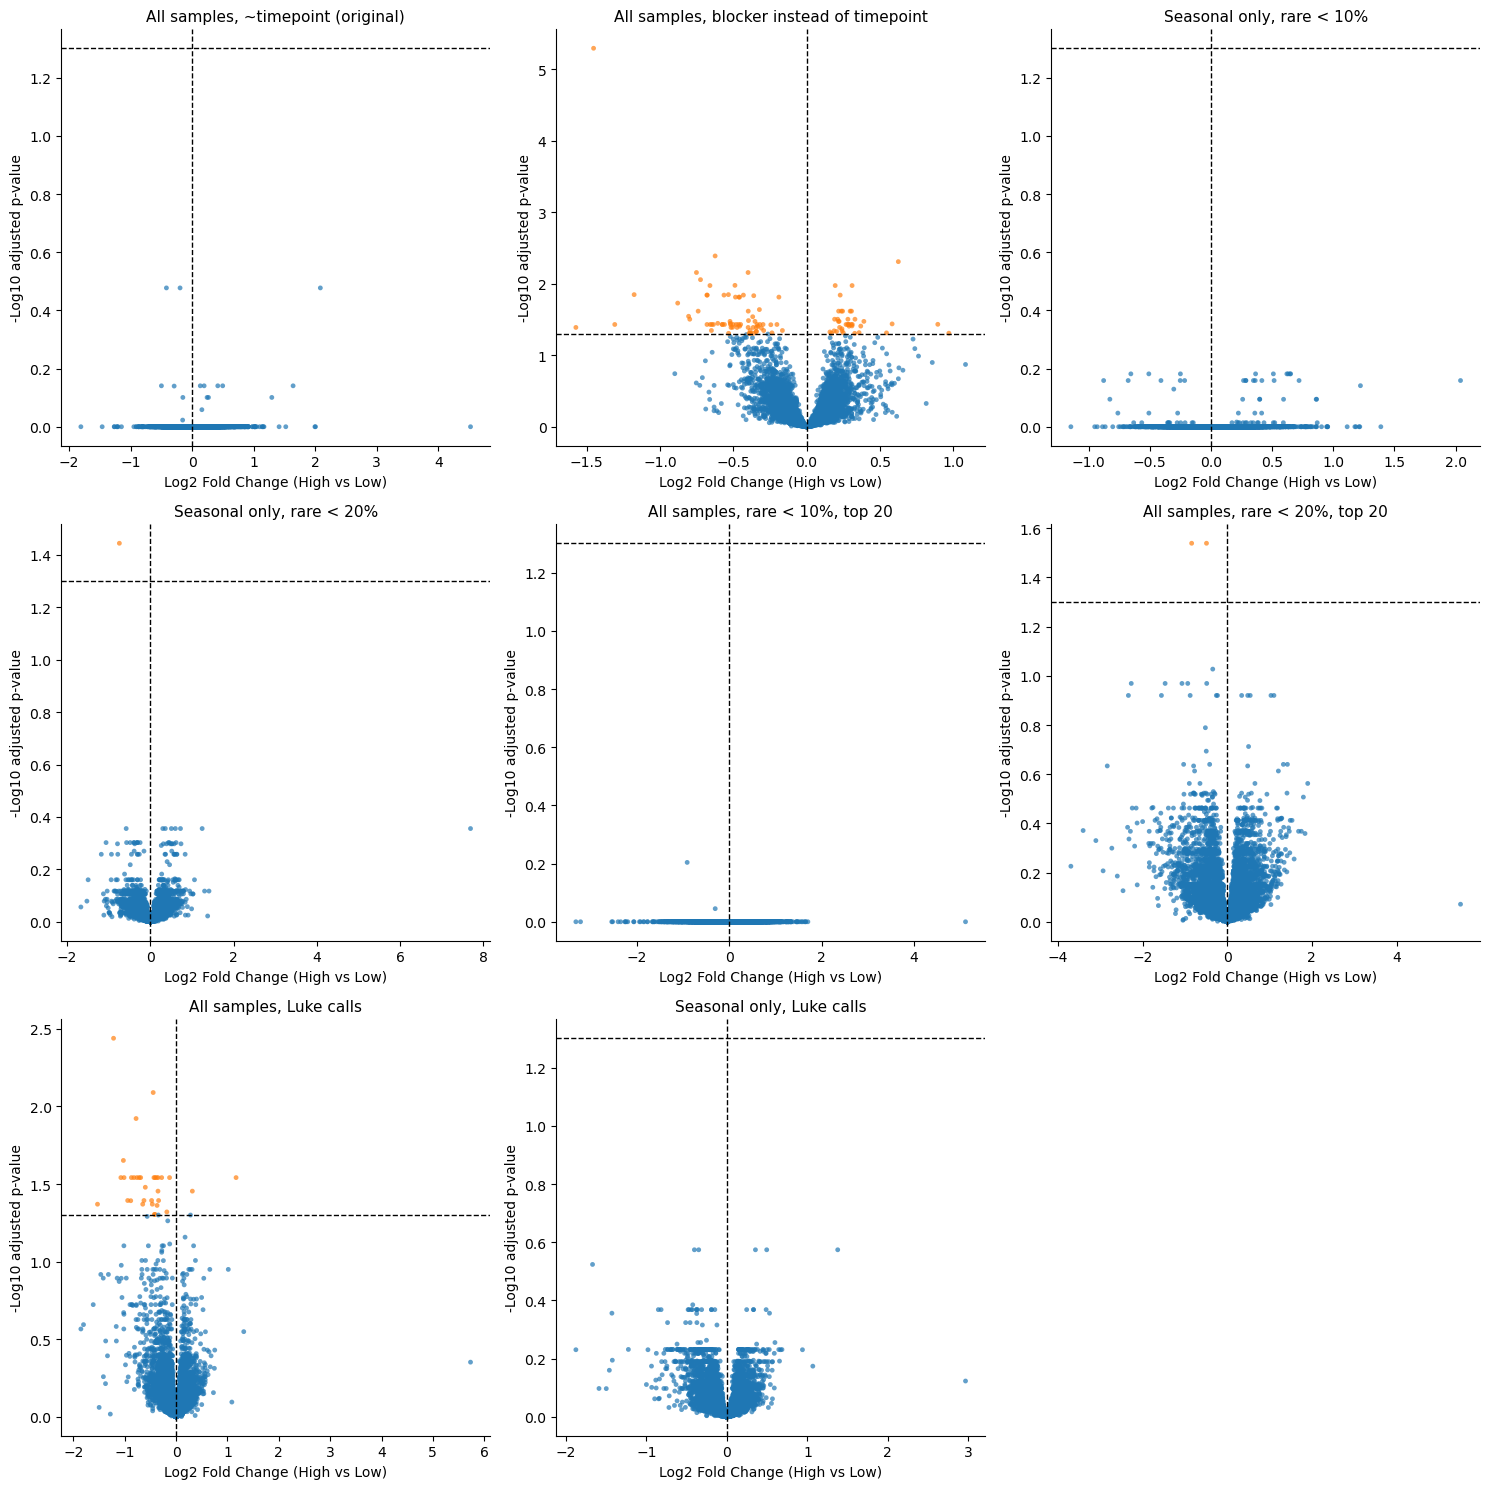

In [11]:
n_cols = 3
n_rows = int(np.ceil(len(run_results) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.flatten()
fig.patch.set_facecolor("white")
for ax, (run_name, results) in zip(axes, run_results.items()):
    volcano_df = results[["log2FoldChange", "padj"]].replace([np.inf, -np.inf], np.nan).dropna()
    volcano_df["neg_log10_padj"] = -np.log10(volcano_df["padj"].clip(lower=1e-300))
    sns.scatterplot(
        data=volcano_df,
        x="log2FoldChange",
        y="neg_log10_padj",
        hue=volcano_df["padj"] < 0.05,
        palette={True: "tab:orange", False: "tab:blue"},
        alpha=0.7,
        s=12,
        linewidth=0,
        legend=False,
        ax=ax,
    )
    ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
    ax.axvline(0, linestyle="--", color="black", linewidth=1)
    ax.set_title(run_name, fontsize=11)
    ax.set_xlabel("Log2 Fold Change (High vs Low)")
    ax.set_ylabel("-Log10 adjusted p-value")
    sns.despine(ax=ax)
for ax in axes[len(run_results):]:
    ax.axis("off")
plt.tight_layout()